# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: MEDJ

# Integrantes
* Matías Agustín Tabak Wolf (273/24)
* Elking Richelieu Mendoza Zambrano (118/25)
* Dante Fongi Martínez (799/24)
* Joaquin Bernardez (959/23)

In [1]:
import moduloALC as alc
import numpy as np
import matplotlib.image as mpimg
import cv2
import os

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**Sistema de la ecuación 6** *(está desarrollado para todas las imágenes pero se puede quitar el for i y determinar un i específico para formar la $\mathbf{Q}$ de una sola foto)*

In [6]:
detected_corners_path = os.path.join('calib','3d','detected_corners.txt')
p_W_corners_path = os.path.join('calib','3d','p_W_corners.txt')

corners = np.loadtxt(p_W_corners_path,delimiter=',')
U, V, W = corners[:,0], corners[:,1], corners[:,2]

G = np.loadtxt(detected_corners_path)

Q = np.zeros((2*corners.shape[0],12))
i = 0
for j in range(corners.shape[0]):
    u = G[i][2*j]
    v = G[i][2*j+1]

    Q[2*j, :] =     [U[j], V[j], W[j], 1,   0,    0,    0,   0, -u*U[j], -u*V[j], -u*W[j], -u]
    Q[2*j + 1, :] = [ 0,    0,    0,   0,  U[j], V[j], W[j], 1, -v*U[j], -v*V[j], -v*W[j], -v]

<u>**Primer pregunta**</u>

Para responderla recurrimos al siguiente teorema:

* **Teorema de Rango-Nulidad** $\longrightarrow$ Sean $V$ y $W$ espacios vectoriales con $dim(V) < +\infty$ y sea $T:V \longrightarrow W$ una transformación lineal entonces $dim(Im(T)) + dim(Nu(T)) = dim(V)$

Considerando que debemos asegurar que hay una solución no nula única a menos de un factor de escala (esto último no interfiere en la consideración del teorema y respuesta del enunciado ya que el conjunto de soluciones es un subespacio y por lo tanto considera a todos sus múltiplos, con hallar una es suficiente y mantiene la propiedad de ser única), sabemos entonces que la $dim(Nu(\mathbf{Q})) = 1$, luego por el teorema podemos despejar $dim(Im(\mathbf{Q}))$, que es quien responde a la pregunta del rango. Por lo mencionado, podemos decir que $dim(Im(\mathbf{Q})) = dim(V) - dim(Nu(\mathbf{Q})) = dim(V) - 1 = 12 - 1 = 11$. El rango que debe tener $\mathbf{Q}$ para asegurar una solución no nula única a menos de un factor de escala es 11.

¿Quien es $V$? ¿Por qué $dim(V) = 12$? Podemos definir a $T$, la transformación lineal que representa nuestra matriz $\mathbf{Q}$, tal que (por las dimensiones de $\mathbf{Q}$) vemos que toma elementos de $R^{12}$ y los lleva a $R^{2n}$, siendo entonces $T:R^{12} \longrightarrow R^{2n}$. Por ello, el espacio de salida es $V = R^{12}$ y $dim(R^{12}) = 12$ $\Longrightarrow$ $dim(V) = 12$.

<u>**Segunda pregunta**</u>

¿Cuántos puntos, como mínimo, aseguran la solución? Prestando atención a esta parte de la pregunta vemos que la misma también se traduce a cuantas filas necesitamos como mínimo para que la respuesta de la anterior pregunta sea válida (o sea, $dim(Im(\mathbf{Q})) = 11$ y, por lo tanto, $dim(Nu(\mathbf{Q})) = 1$) ¿Por qué filas si nos preguntan puntos? Porque cada par de filas en la matriz $\mathbf{Q}$ representa un punto, y además sabemos que el rango de una matriz (que es igual a la dimensión de la imagen de la matriz) es mayor o igual a uno y menor o igual a la cantidad de filas de ella. Por lo que podemos concluir que $dim(Im(\mathbf{Q})) = 11 \leq 2n$, más específicamente: $\frac{11}{2} = 5.5 \leq n$. Entonces (considerando que $n$ es un número natural) la cantidad de puntos mínimos que aseguran la solución son $6$. 

¿Y qué condición deben cumplir? Como $dim(Im(\mathbf{Q})) = 11$ entonces sabemos que las filas deben de ser linealmente independientes entre sí, ya que le hallamos un techo al decir que $n = 6$ por lo menos, pero también debemos garantizar su piso para que la dimensión del núcleo no crezca (ya que de esa manera perderiamos la condición $dim(Nu(\mathbf{Q})) = 1$ y sería mayor a uno). Para ello, la matriz $\mathbf{Q}$ es una matriz que tiene 11 filas necesariamente linealmente independientes. Traduciendo esa información a los puntos $U,V,W$ logramos entender que será necesario que hayan 6 puntos no coplanares, o sea que hayan 6 puntos distribuidos de tal manera que no exista un plano que pueda contenerlos a la vez.

<u>**Hallar el vector**</u> $\mathbf{m}$

Sea $Q = U \Sigma V^*$ su descomposición SVD.

$\min\limits_{\mathbf{m}}$ $\|\mathbf{Qm}\|^2$ = $\min\limits_{\mathbf{m}}$ $\|U \Sigma V^* m\|^2$

Dado que $U$ y $V^*$ son unitarias sabemos que $\|\mathbf{Ux}\| = \|\mathbf{x}\|$ y $\|\mathbf{V^*x}\| = \|\mathbf{x}\|$ $\forall x \in R^n$, por lo que podemos reescribir la anterior expresión de la siguiente manera

$\min\limits_{\mathbf{m}}$ $\|\Sigma V^* m\|^2$

Definiendo $y = V^* m$, podemos concluir que $\|y\| = \|V^* m\| = \|m\| = 1$ pues, por enunciado, $\|m\| = 1$. Entonces lo anterior es igual a 

$\min\limits_{\mathbf{y}}$ $\|\Sigma y\|^2$

Como $\|y\| = 1$, $\sigma_n$ es el valor singular más pequeño en $\Sigma$ y nos interesa hallar el vector que minimice la expresión, podemos considerar $y = \mathbf{e_{12}}$, quedando como resultado de la multiplicacion $\Sigma y$, el vector $(0,...,\sigma_n)$.

Volviendo a nuestra reescritura previa obtenemos que $V^* m = \mathbf{e_{12}}$, por lo que el $m$ deseado que minimiza la ecuación 6 es $m = V\mathbf{e_{12}} = v_n$ (siendo $v_n$ la columna $n$ de la matriz $V$).

Sabemos que $V^*$ unitaria $\Longrightarrow V$ es unitaria. Lo anterior quiere decir que las columnas de $V$ también forman una $BON$ (Base Ortonormal), por lo que cada columna tiene norma igual a uno y vale que $\|m\| = \|v_n\| = 1$.

$\therefore$ El $m$ que resuelve $\min\limits_{\mathbf{m}} \|\mathbf{Qm}\|^2$ es $m = v_n$

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



**a)**

In [7]:
def obtenerQ3d(imPts, objtPts):
    """
    Parámetros que recibe: imPts, un array con 24 columnas que contiene de a pares las coordenadas en el plano imagen asociados a los puntos del mundo real; objPts, un array de 3 columnas y 12 filas, cada fila hace referencia a las coordenadas en el mundo real de un punto (siendo cada columna el elemento correspondiente a la coordenada).
    Output esperado: matriz de calibración Q de 2nx12 dada por el marco teórico.  
    """
    U, V, W = objtPts[:,0], objtPts[:,1], objtPts[:,2]

    Q = np.zeros((2*objtPts.shape[0],12))

    for j in range(objtPts.shape[0]):

        u = imPts[2*j]
        v = imPts[2*j+1]

        Q[2*j, :] =     [U[j], V[j], W[j], 1,   0,    0,    0,   0, -u*U[j], -u*V[j], -u*W[j], -u]
        Q[2*j + 1, :] = [ 0,    0,    0,   0,  U[j], V[j], W[j], 1, -v*U[j], -v*V[j], -v*W[j], -v]
        

    return Q

**b)**

In [ ]:
def resolverDLT3D(Q):
    '''
    Parámetros que recibe: la matriz de calibración Q de 2nx12.
    Output esperado: la matriz M que es igual a K[R t].
    '''
    #Dado que en el mundo real no existe un vector m distinto de cero en el núcleo de Q, entonces por la demostración dada en el punto (1b) vemos que podemos obtener M tomando la última columna de la matriz V, siendo V la matriz dada en la desomposición SVD de la matriz Q del input.
    hatU, hatSig, hatV = alc.svd_reducida(Q,'max',1e-15) 
    M = hatV[:,-1] 
    M = np.reshape(M,(3,4)) #Como el resultado se obtiene de considerar a M vectorizado, una vez obtenido aplicamos un reshape para darle la forma matricial original correspondiente.
    return M

**c y d)**

In [ ]:
def devolverMatricesCalibracion3d(M,op=(False,False)):
    '''
    Parámetros que recibe: M, la matriz dada por la múltplicación de las variables extrínsecas e instrínsecas de la cámara; y op, una tupla de booleanos (de forma predeterminada con dos False) que al indicarle True en alguna o ambas de sus posiciones impone que el sesgo sea nulo y/o la igualdad entre los alpha_u y alpha_v.
    Output esperado: R,t,K las variables extrínsecas e intrínsecas de la cámara.
    '''
    #Dado que queremos hallar K, R y t tal que M = K[R t] pensamos al lado derecho de la igualdad como una multplicación por bloques obteniendo que M = [KR | Kt] = [A | b]. Con esta última reesctritura (A = KR y b = Kt) podemos despejar y hallar cada matriz deseada.
    A = M[:,:3]
    b = M[:,3]

    #Definimos una matriz que permute las filas y columnas (dependiendo de por cual lado se multiplique) y que nos será útil para, con cálculos algebráicos, obtener el output deseado.
    P = np.array([[0,0,1],
                  [0,1,0],
                  [1,0,0]])

    At = alc.traspuesta(A)
    PAt = alc.arroba(P,At)
    PAtP = alc.arroba(PAt,P)

    q,r = alc.QR_con_HH(PAtP)

    rt = alc.traspuesta(r)
    Prt = alc.arroba(P,rt)
    K = alc.arroba(Prt,P) 

    #K = K/K[2][2]

    qt = alc.traspuesta(q)
    Pqt = alc.arroba(P,qt)
    R = alc.arroba(Pqt,P)

    for s in range(3):
        if K[s][s] < 0:
            K[:,s] = (-1)*K[:,s]
            R[s,:] = (-1)*R[s,:]

    Kinv = alc.inversa(K)
    t = alc.arroba(Kinv,b)

    #K = K/K[2][2]

    if op[0] == True:
        K[0][0] = K[1][1]
    if op[1] == True:
        K[0][1] = 0

    return R,t,K

In [36]:
######### COMPARAR VERSIONES de devolverMatricesCalibracion3d ############

"""
1 --> Multiplicando con alc.arroba()
2 --> MUltiplicando con @
3 --> Multiplicando dentro de la función 

equivalentes 
"""

Q_prueba = obtenerQ3d(G[0], corners)

M_prueba = resolverDLT3D(Q_prueba)

R_test, t_test, K_test = devolverMatricesCalibracion3d(M_prueba)
#R_test_2, t_test_2, K_test_2 = devolverMatricesCalibracion3d_2(M_prueba)
#R_test_3, t_test_3, K_test_3 = devolverMatricesCalibracion3d_3(M_prueba)

def armar_Rt(R, t):
    t_columna = np.reshape(t, (3, 1)) 
    return np.hstack((R, t_columna))


print('\n M con t grande: ')
#print(K_test_3 @ armar_Rt(R_test_3,t_test_3)) # -------> M 


print('\n M con t chica: ')
print(K_test @ armar_Rt(R_test, t_test))


print('\n M original: ')
print(M_prueba)


 M con t grande: 

 M con t chica: 
[[-5.11807767e+02 -1.80809927e+02  1.11039070e+02 -8.37825121e-01]
 [-2.93580176e+01 -4.84279565e+02 -1.04118952e+02 -5.37810986e-01]
 [-7.01233460e-01 -3.54940167e-01 -6.18295327e-01 -5.11440314e-03]]

 M original: 
[[-6.44865266e-02 -2.27816085e-02  1.39906512e-02 -8.37825121e-01]
 [-3.69903839e-03 -6.10180404e-02 -1.31187333e-02 -5.37810986e-01]
 [-8.83537006e-05 -4.47215927e-05 -7.79036987e-05 -5.11440314e-03]]


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

Para responderla recurrimos al siguiente teorema:

* **Teorema de Rango-Nulidad** $\longrightarrow$ Sean $V$ y $W$ espacios vectoriales con $dim(V) < +\infty$ y sea $T:V \longrightarrow W$ una transformación lineal entonces $dim(Im(T)) + dim(Nu(T)) = dim(V)$

Considerando que debemos asegurar que hay una solución no nula única a menos de un factor de escala (esto último no interfiere en la consideración del teorema y respuesta del enunciado ya que el conjunto de soluciones es un subespacio y por lo tanto considera a todos sus múltiplos, con hallar una es suficiente y mantiene la propiedad de ser única), sabemos entonces que la $dim(Nu(\mathbf{Q})) = 1$, luego por el teorema podemos despejar $dim(Im(\mathbf{Q}))$, que es quien responde a la pregunta del rango. Por lo mencionado, podemos decir que $dim(Im(\mathbf{Q})) = dim(V) - dim(Nu(\mathbf{Q})) = dim(V) - 1 = 9 - 1 = 8$. El rango que debe tener $\mathbf{Q}$ para asegurar una solución no nula única a menos de un factor de escala es 8.

¿Quien es $V$? ¿Por qué $dim(V) = 9$? Podemos definir a $T$, la transformación lineal que representa nuestra matriz $\mathbf{Q}$, tal que (por las dimensiones de $\mathbf{Q}$) vemos que toma elementos de $R^9$ y los lleva a $R^{2n}$, siendo entonces $T:R^9 \longrightarrow R^{2n}$. Por ello, el espacio de salida es $V = R^9$ y $dim(R^9) = 9$ $\Longrightarrow$ $dim(V) = 9$.

In [ ]:
def obtenerQ2d(imgPts, objPts):

    U, V= objPts[:,0], objPts[:,1]
    L = []
    for j in range(objPts.shape[0]):
        L.append([U[j],V[j],1] + [0,0,0] + [-imgPts[2*j]*U[j],-imgPts[2*j]*V[j],-imgPts[2*j]])
        L.append([0,0,0] + [U[j],V[j],1] + [-imgPts[2*j+1]*U[j],-imgPts[2*j+1]*V[j],-imgPts[2*j+1]])

    Q = np.array(L)

    return Q

In [ ]:
def armarA(Hlst):
    a = []
    for H in Hlst:
        c1,c2 = H[:,0],H[:,1]
        v12 = [c1[0]*c2[0],c1[0]*c2[1] + c1[1]*c2[0],c1[1]*c2[1],c1[2]*c2[0] + c1[0]*c2[2],c1[2]*c2[1] + c1[1]*c2[2],c1[2]*c2[2]]
        v1122 = [c1[0]*c1[0] - c2[0]*c2[0],
                 c1[0]*c1[1] + c1[1]*c1[0] - c2[0]*c2[1] - c2[1]*c2[0],
                 c1[1]*c1[1] - c2[1]*c2[1],
                 c1[2]*c1[0] + c1[0]*c1[2] - c2[2]*c2[0] - c2[0]*c2[2],
                 c1[2]*c1[1] + c1[1]*c1[2] - c2[2]*c2[1] - c2[1]*c2[2],
                 c1[2]*c1[2] - c2[2]*c2[2]]
        a.append(v12)
        a.append(v1122)

    A = np.array(a)

    return A

In [ ]:
def calcularMatrizK2D(A):
    hatU, hatSig, hatV = alc.svd_reducida(A)
    b = hatV[-1,:]
    B = np.array([[b[0],b[1],b[3]],[b[1],b[2],b[4]],[b[3],b[4],b[5]]])

    if not alc.esSDP(B):
        B = (-1)*B

    L,D,V = alc.calculaLDV(B)

    for i in range(D.shape[0]):
        V[:,i] = V[:,i]*np.sqrt(D[i][i]) 

    K = alc.inversa(V)
    K = K/K[2,2]
    
    return K

In [ ]:
def obtenerPose2D(Hj, K):
    Kinv = alc.inversa(K)
    C1,C2,C3 = Hj[:,0],Hj[:,1],Hj[:,2]
    KinvC1,KinvC2,KinvC3 = np.zeros(Kinv.shape[0]),np.zeros(Kinv.shape[0]),np.zeros(Kinv.shape[0])

    for i in range(Kinv.shape[0]):
        valor1,valor2,valor3 = 0,0,0
        for k in range(Kinv.shape[1]):
            valor1 += Kinv[i][k]*C1[k]
            valor2 += Kinv[i][k]*C2[k]
            valor3 += Kinv[i][k]*C3[k] 
        KinvC1[i] = valor1
        KinvC2[i] = valor2
        KinvC3[i] = valor3

    λ = 1/alc.norma(KinvC1,2)
    r1 = λ*KinvC1
    r2 = λ*KinvC2
    r3 = np.array([r1[1]*r2[2]-r1[2]*r2[1],-r1[0]*r2[2]+r1[2]*r2[0],r1[0]*r2[1]-r1[1]*r2[0]])
    Rj = np.zeros((3,3))
    Rj[:,0], Rj[:,1], Rj[:,2] = r1,r2,r3
    tj = λ*KinvC3
    return Rj,tj

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [55]:
def obtenerQ2d(imgPts, objPts):

    U, V= objPts[:,0], objPts[:,1]
    L = []
    for j in range(objPts.shape[0]):
        L.append([U[j],V[j],1] + [0,0,0] + [-imgPts[2*j]*U[j],-imgPts[2*j]*V[j],-imgPts[2*j]])
        L.append([0,0,0] + [U[j],V[j],1] + [-imgPts[2*j+1]*U[j],-imgPts[2*j+1]*V[j],-imgPts[2*j+1]])

    Q = np.array(L)

    return Q

iP = np.array([193,171,841,190,154,232,869,251,511,318,386,177,652,185])
oP = np.array([[105,43.16],[105,24.8],[99.5,43.16],[99.5,24.8],[94,34],[105,37.66],[105,30.34]])

Q = obtenerQ2d(iP,oP)

def resolverDLT2D(A):
    '''
    Parámetros que recibe:
    Que retornará:
    (Recordar comentar el código y dar a las variables nombres explicativos)
    '''
    hatU, hatSig, hatV = alc.svd_reducida(A)
    M = hatV[:,-1]
    M = np.reshape(M,(3,3))
    return M

H = resolverDLT2D(Q)

Hinv = alc.inversa(H)

#CORREGIR EL ARROBA, PONER LA MULTPLICACION PERMITIDA
v = Hinv@np.array([813,546,1])
v = v/v[2]
print(v)

d = (np.array([105,30.34,1]) - v)
print(d)
res = alc.norma(d,2)
print(res)

[82.5357867  28.24002863  1.        ]
[22.4642133   2.09997137  0.        ]
22.562153244634022


In [ ]:
j1 = Hinv@np.array([101,534,1])
j2 = Hinv@np.array([243,403,1])
j3 = Hinv@np.array([376,324,1])
j4 = Hinv@np.array([382,295,1])
j5 = Hinv@np.array([844,349,1])
j6 = Hinv@np.array([813,546,1])

j1 = j1/j1[2]
j2 = j2/j2[2]
j3 = j3/j3[2]
j4 = j4/j4[2]
j5 = j5/j5[2]
j6 = j6/j6[2]

[92.46921465 26.37599102  1.        ]


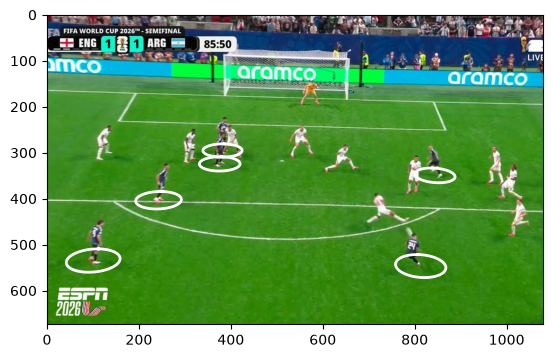

In [75]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Tu lectura que convierte BGR a RGB mediante slicing
img = cv2.imread('futbol/test-gol-enzo.png')[:, :, ::-1]

# 1. Definir los ángulos para los bordes del círculo
theta = np.linspace(0, 2 * np.pi, 100)

# 2. Cargar tu imagen de fondo
plt.imshow(img)

# 3. Agrupar los vectores (X, Y, 1) que ya calculaste en la cancha
jugadores = [j1, j2, j3, j4, j5, j6]

for j in jugadores:
    # Generamos los puntos del círculo de radio 1 metro en la cancha
    pts_X_cancha = j[0] + 1 * np.cos(theta)
    pts_Y_cancha = j[1] + 1 * np.sin(theta)
    unos = np.ones_like(pts_X_cancha)
    
    # Matriz homogénea del círculo en la cancha (3 filas x 100 columnas)
    circulo_cancha = np.array([pts_X_cancha, pts_Y_cancha, unos])
    
    # Proyectamos los puntos hacia la foto usando la matriz de homografía directa H
    # (Recordá cambiar el @ por tu función permitida de multiplicación si hace falta)
    circulo_img = H @ circulo_cancha
    
    # Normalizamos dividiendo las coordenadas proyectadas por el factor de escala w
    u_img = circulo_img[0, :] / circulo_img[2, :]
    v_img = circulo_img[1, :] / circulo_img[2, :]
    
    # Dibujamos la elipse blanca
    plt.plot(u_img, v_img, color='white', linewidth=2)

plt.show()

In [77]:
def obtenerQ2d(imgPts, objPts):

    U, V= objPts[:,0], objPts[:,1]
    L = []
    for j in range(objPts.shape[0]):
        L.append([U[j],V[j],1] + [0,0,0] + [-imgPts[2*j]*U[j],-imgPts[2*j]*V[j],-imgPts[2*j]])
        L.append([0,0,0] + [U[j],V[j],1] + [-imgPts[2*j+1]*U[j],-imgPts[2*j+1]*V[j],-imgPts[2*j+1]])

    Q = np.array(L)

    return Q

iP = np.array([733,316,731,759,1227,389,1363,577,1008,473,1474,387])
oP = np.array([[88.5,54.16],[88.5,13.84],[99.5,43.16],[99.5,24.84],[94,34],[105,43.16]])

Q = obtenerQ2d(iP,oP)

def resolverDLT2D(A):
    '''
    Parámetros que recibe:
    Que retornará:
    (Recordar comentar el código y dar a las variables nombres explicativos)
    '''
    hatU, hatSig, hatV = alc.svd_reducida(A)
    M = hatV[:,-1]
    M = np.reshape(M,(3,3))
    return M

H = resolverDLT2D(Q)

Hinv = alc.inversa(H)

v = Hinv@np.array([827,326,1])
v = v/v[2]
print(v)

[90.82916162 52.40493596  1.        ]


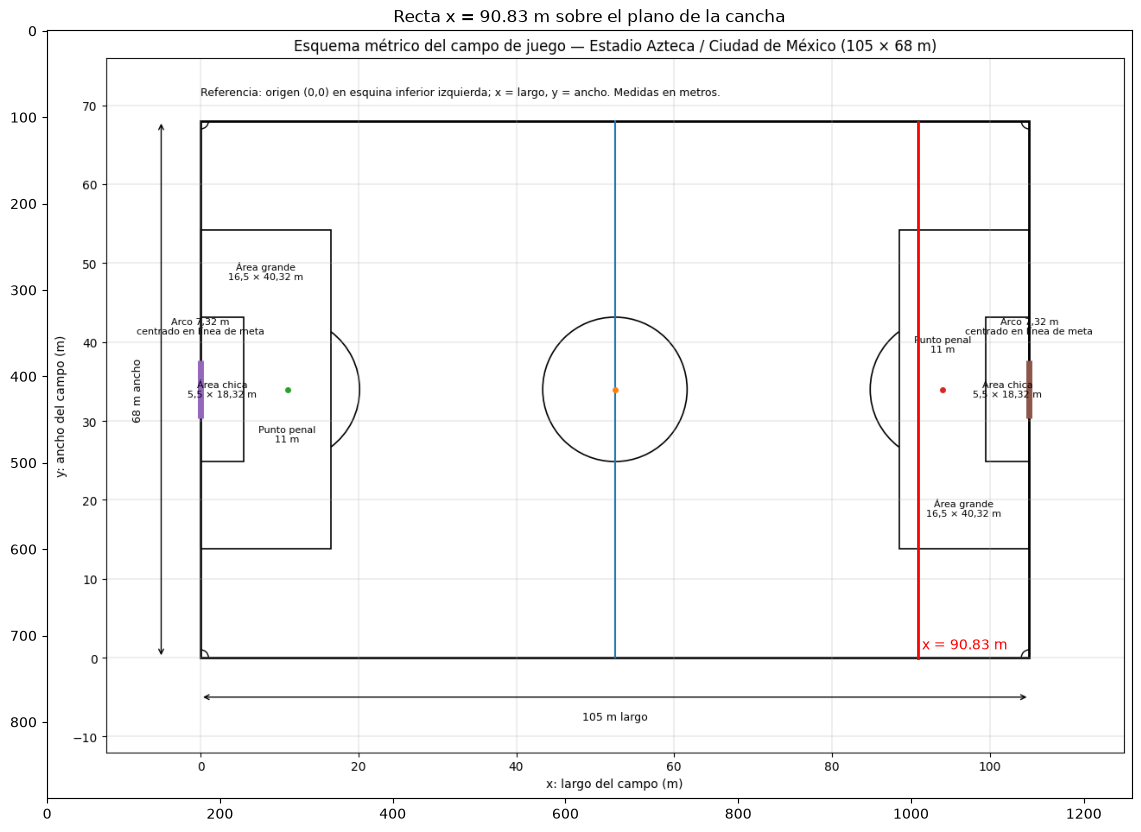

In [85]:
plano = cv2.imread('futbol/estadio_azteca.png')[:, :, ::-1]   # BGR -> RGB

# Calibración del plano: píxeles donde están los bordes de la cancha en la imagen
COL_X0, COL_X105 = 178, 1137     # columnas de x = 0 m y x = 105 m
FILA_Y0, FILA_Y68 = 726, 105     # filas de y = 0 m y y = 68 m

def metrosAPixelPlano(U, V):
    '''Convierte un punto de la cancha (en metros) a píxeles de la imagen del plano.'''
    u = COL_X0 + (COL_X105 - COL_X0) * U / 105
    v = FILA_Y0 - (FILA_Y0 - FILA_Y68) * V / 68     # la fila crece hacia abajo
    return u, v

x_recta = 90.8291

# Extremos de la recta: de un lateral (y = 0) al otro (y = 68)
u1, v1 = metrosAPixelPlano(x_recta, 0)
u2, v2 = metrosAPixelPlano(x_recta, 68)

plt.figure(figsize=(14, 10))
plt.imshow(plano)
plt.plot([u1, u2], [v1, v2], color='red', linewidth=2)
plt.text(u1 + 5, v1 - 10, 'x = %.2f m' % x_recta, color='red')
plt.title('Recta x = %.2f m sobre el plano de la cancha' % x_recta)
plt.show()

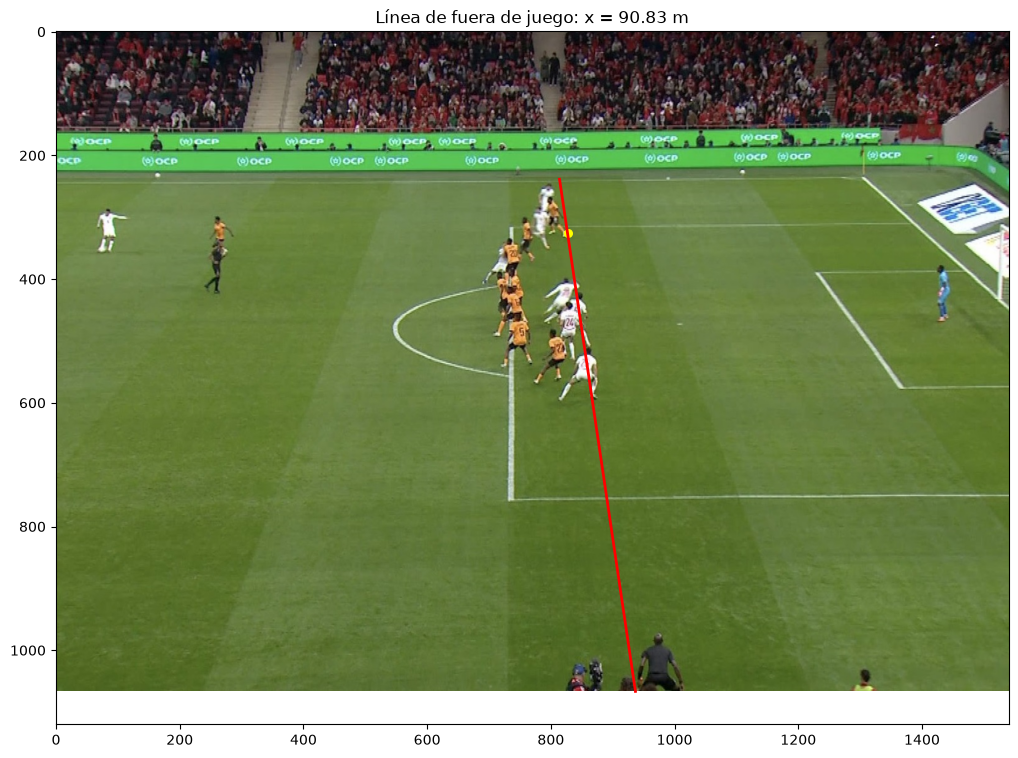

In [86]:
img = cv2.imread('futbol/test-fuera-de-juego.png')[:, :, ::-1]   # BGR -> RGB
alto, ancho = img.shape[0], img.shape[1]

x_offside = v[0]      # 90.8291: la x del pie del último defensor, en metros

# Puntos de la recta x = x_offside en la cancha, de un lateral (y = 0) al otro (y = 68)
y_cancha = np.arange(0, 68.1, 0.1)
puntos_cancha = np.vstack([x_offside + 0 * y_cancha,      # x constante
                           y_cancha,
                           np.ones(y_cancha.shape[0])])

# Proyección a la foto con H
puntos_img = H @ puntos_cancha
u = puntos_img[0, :] / puntos_img[2, :]
v_img = puntos_img[1, :] / puntos_img[2, :]

# Nos quedamos con los puntos que caen dentro de la foto
dentro = (u >= 0) & (u < ancho) & (v_img >= 0) & (v_img < alto)

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(u[dentro], v_img[dentro], color='red', linewidth=2)
plt.scatter(827, 326, c='yellow', s=30)     # pie del último defensor
plt.title('Línea de fuera de juego: x = %.2f m' % x_offside)
plt.show()

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---